# Figure 3 Supplement 4: Recovery of each subject's stopping-model parameters

Can the stopping model's parameters be estimated reliably for these subjects,
at their own parameter values and with their own amounts of data? Each OL
subject was simulated `NUM_REPS` = 10 times from their main fit, on their real
trial structure (same blocks, trial counts, SNRs and step statistics), and each
simulated data set was refit with the same procedure
(`scripts/run_stopping_bootstrap.py`).

Each cell: Spearman correlation across subjects between the parameter used to
simulate and the median of its 10 refits.

- **A — parameters fit separately in each block:** bound plateau, bound
  variability (CV of the trial-to-trial bound), guess, lapse and anticipation
  rates. Columns: OL low-SNR blocks 1–3. Subject-blocks whose plateau sits at a
  fit limit are left out (counts printed).
- **B — parameters shared across a subject's blocks:** start height (bound at
  step 1 relative to the plateau, log), time of the fall to the plateau, slope
  of the bound after the fall (log units per step), sensory noise, and the
  probability of a one-step non-decision time (vs. two steps).

Refits that did not converge are left out (counts printed). The table also
gives each parameter's median per-subject spread of refits (10th–90th
percentile), used for error bars elsewhere.


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import get_plateau_at_limit

PROCESSED = Path('../data/processed')

In [2]:
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}
PER_BLOCK = {'bound_scale': 'Bound plateau', 'bound_cv': 'Bound variability', 'guess_rate': 'Guess rate',
             'lapse_rate': 'Lapse rate', 'anticipation_rate': 'Anticipation rate'}
SHARED = {'log_h_start': 'Start height', 'knee': 'Time of fall', 'late_slope': 'Slope after the fall',
          'sensory_std': 'Sensory noise', 'ndt_p1': 'P(1-step non-decision time)'}

boot = pd.read_pickle(PROCESSED / 'stopping_bootstrap.pkl')
boot = boot[boot.task == 'OL']
n_fail = boot[~boot.success].groupby(['subject_index', 'rep']).ngroups
print(f'{n_fail} of {boot.groupby(["subject_index", "rep"]).ngroups} OL refits did not converge (left out)')
boot = boot[boot.success]
true = boot.groupby(['subject_index', 'group']).first()[[f'{p}_true' for p in {**PER_BLOCK, **SHARED}]]
fit = boot.groupby(['subject_index', 'group'])[[f'{p}_fit' for p in {**PER_BLOCK, **SHARED}]]
med, q10, q90 = fit.median(), fit.quantile(0.1), fit.quantile(0.9)

lim = pd.DataFrame({'bound_scale': true.bound_scale_true, 'group': true.index.get_level_values('group'),
                    'subject_index': true.index.get_level_values('subject_index')})
l_lim = get_plateau_at_limit(lim).to_numpy() & true.index.get_level_values('group').isin(BLOCKS)
print(f'per-block parameters: left out {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: '
      f'{list(true.index[l_lim])}')

def _rho(t, m):
    ok = np.isfinite(t) & np.isfinite(m)
    return scipy.stats.spearmanr(t[ok], m[ok]).statistic, int(ok.sum())

def _spread(t, lo, hi):
    return np.median((hi - lo) / np.abs(t))

rows, rho_block = [], pd.DataFrame(index=list(PER_BLOCK), columns=BLOCKS, dtype=float)
for p, label in PER_BLOCK.items():
    for b in BLOCKS:
        l = (true.index.get_level_values('group') == b) & ~l_lim
        r, n = _rho(true.loc[l, f'{p}_true'], med.loc[l, f'{p}_fit'])
        rho_block.loc[p, b] = r
        rows.append({'parameter': label, 'block': b, 'subjects': n, 'Spearman rho': r,
                     'median relative 10-90% spread': _spread(true.loc[l, f'{p}_true'], q10.loc[l, f'{p}_fit'],
                                                              q90.loc[l, f'{p}_fit'])})
first = true.groupby(level='subject_index').head(1).index    # shared parameters: one row per subject
rho_shared = pd.Series(index=list(SHARED), dtype=float)
for p, label in SHARED.items():
    r, n = _rho(true.loc[first, f'{p}_true'], med.loc[first, f'{p}_fit'])
    rho_shared[p] = r
    rows.append({'parameter': label, 'block': 'all', 'subjects': n, 'Spearman rho': r,
                 'median relative 10-90% spread': _spread(true.loc[first, f'{p}_true'], q10.loc[first, f'{p}_fit'],
                                                          q90.loc[first, f'{p}_fit'])})
display(pd.DataFrame(rows).round(3))

0 of 600 OL refits did not converge (left out)
per-block parameters: left out 5 subject-blocks with the plateau at a fit limit: [(13, 'B3'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (59, 'B1')]


,parameter,block,subjects,Spearman rho,median relative 10-90% spread
0,Bound plateau,B1,58,0.992,0.273
1,Bound plateau,B2,59,0.994,0.199
2,Bound plateau,B3,57,0.886,0.266
3,Bound variability,B1,58,0.962,0.702
4,Bound variability,B2,59,0.974,0.517
5,Bound variability,B3,57,0.957,0.665
6,Guess rate,B1,58,0.991,0.730
7,Guess rate,B2,59,0.978,1.302
8,Guess rate,B3,57,0.943,2.353
9,Lapse rate,B1,58,0.968,1.370


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


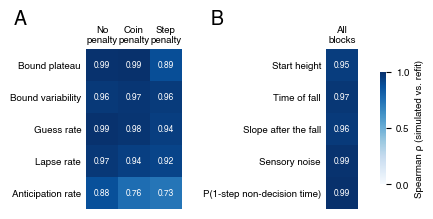

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S04.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
CMAP = 'Blues'

fig = plt.figure(figsize=(11 * CM, 5.2 * CM))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[3, 1], wspace=2.2, left=0.2, right=0.83, bottom=0.08,
                       top=0.86)
axA, axB = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

def _heatmap(ax, values, ylabels, xlabels):
    im = ax.imshow(values, cmap=CMAP, vmin=0, vmax=1, aspect='equal')
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, f'{v:.2f}'.replace('-', '\u2212'), ha='center', va='center', fontsize=6,
                color='w' if v > 0.6 else 'k')
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_xticks(range(len(xlabels)), xlabels)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

_heatmap(axA, rho_block.to_numpy(), list(PER_BLOCK.values()), [BLOCK_TITLES[b].replace(' ', '\n') for b in BLOCKS])
im = _heatmap(axB, rho_shared.to_numpy()[:, None], list(SHARED.values()), ['All\nblocks'])
cax = fig.add_axes([0.88, 0.2, 0.015, 0.55])
cb = fig.colorbar(im, cax=cax, ticks=[0, 0.5, 1])
cb.set_label('Spearman ρ (simulated vs. refit)')
cb.outline.set_visible(False)
add_panel_label(axA, 'A', dx=-0.75, dy=1.25)
add_panel_label(axB, 'B', dx=-3.6, dy=1.25)

out = FIGURES_DIR / 'Figure03_S04.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)